# 02: Retention, RFM and delivery impact

Input: data/processed/orders_enriched.csv (one row per order, built in notebook 01).
Rules: customers are identified by customer_unique_id; canceled and unavailable orders are excluded;
the cohort window is 2017-01 to 2018-08 (2016 and the last two months of 2018 are incomplete).

In [1]:
from pathlib import Path

import pandas as pd
from dotenv import find_dotenv

repo = Path(find_dotenv(usecwd=True)).parent
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = pd.read_csv(repo / "data" / "processed" / "orders_enriched.csv", parse_dates=date_cols)

print("shape:", orders.shape)
print("one row per order:", orders["order_id"].is_unique)
print("orders with order_number:", orders["order_number"].notna().sum())
print("purchase column type:", orders["order_purchase_timestamp"].dtype)

shape: (99441, 18)
one row per order: True
orders with order_number: 98207
purchase column type: datetime64[ns]


**Check:** orders_enriched.csv loads with 99,441 orders and 18 columns, one row per order, and the
dates parse as datetimes. 98,207 orders have an order_number (canceled and unavailable orders are
excluded), the same count as SQL Query 13.

In [2]:
first = orders[orders["order_number"] == 1].copy()
first["cohort_month"] = first["order_purchase_timestamp"].dt.to_period("M")
cohort_size = first.groupby("cohort_month").size()

print("people with a first order:", len(first))
print("people who ordered again:", (first["person_total_orders"] > 1).sum())
print(cohort_size)

people with a first order: 94990
people who ordered again: 2888
cohort_month
2016-09       2
2016-10     290
2016-12       1
2017-01     752
2017-02    1690
2017-03    2571
2017-04    2325
2017-05    3541
2017-06    3102
2017-07    3822
2017-08    4130
2017-09    4075
2017-10    4392
2017-11    7190
2017-12    5439
2018-01    6951
2018-02    6357
2018-03    6931
2018-04    6698
2018-05    6586
2018-06    5920
2018-07    6016
2018-08    6209
Freq: M, dtype: int64


**Insight:** 94,990 people have a first order, and 2,888 of them (3.04%) ordered again, matching SQL
Query 13. The 2016 cohorts are tiny (2, 290 and 1 people, November missing), so the usable window is
2017-01 to 2018-08: 20 cohorts and 94,697 people. The largest cohort is 2017-11 (7,190 people), and the
2018 cohorts stay between 5,920 and 6,951, in line with the flat revenue seen earlier. There is no
cohort for 2018-09 or 2018-10, because nobody's first valid order falls in those months (cause not checked).

In [3]:
valid = orders[orders["order_number"].notna()].copy()
valid["order_month"] = valid["order_purchase_timestamp"].dt.to_period("M")
valid = valid.merge(first[["customer_unique_id", "cohort_month"]], on="customer_unique_id", how="left")

valid["months_since_first"] = ((valid["order_month"].dt.year - valid["cohort_month"].dt.year) * 12
                               + (valid["order_month"].dt.month - valid["cohort_month"].dt.month))

active = (valid.groupby(["cohort_month", "months_since_first"])["customer_unique_id"].nunique()
          .unstack(fill_value=0))

print("rows:", len(valid))
print("repeat orders (order_number > 1):", (valid["order_number"] > 1).sum())
print("repeat orders in the same month as the first order:",
      ((valid["order_number"] > 1) & (valid["months_since_first"] == 0)).sum())
print("month 0 equals cohort size for every cohort:", (active[0] == cohort_size).all())

rows: 98207
repeat orders (order_number > 1): 3217
repeat orders in the same month as the first order: 1273
month 0 equals cohort size for every cohort: True


**Insight:** 98,207 orders belong to 94,990 people, which leaves 3,217 repeat orders, about 1.11 per
repeat buyer (2,888). Month 0 equals the cohort size for every cohort, so the counting is consistent.
1,273 repeat orders (39.6%) happen in the same calendar month as the first order. Caution: the matrix
counts people active in each month, so someone who bought again in the first month is not visible in
month 1 or later, and the later columns understate how many people ever returned.

In [9]:
last_month = pd.Period("2018-08", freq="M")

cohort_size_w = cohort_size.loc["2017-01":"2018-08"]
active_w = active.loc["2017-01":"2018-08"]
active_w = active_w.reindex(columns=range(0, 20), fill_value=0)   # months 0 to 19, no gaps

# retention in percent: active people / cohort size * 100
retention = active_w.div(cohort_size_w, axis=0) * 100

# months of data available after each cohort's first month
months_available = (last_month.year - cohort_size_w.index.year) * 12 + (last_month.month - cohort_size_w.index.month)

# blank out months that have not happened yet (NaN, not 0)
for cohort, max_m in zip(retention.index, months_available):
    retention.loc[cohort, retention.columns > max_m] = float("nan")

print(retention.columns.tolist())
print(retention.round(2).iloc[:5, :6])

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
months_since_first      0     1     2     3     4     5
cohort_month                                           
2017-01             100.0  0.40  0.27  0.13  0.40  0.13
2017-02             100.0  0.24  0.30  0.12  0.41  0.12
2017-03             100.0  0.51  0.35  0.39  0.35  0.16
2017-04             100.0  0.60  0.22  0.17  0.30  0.26
2017-05             100.0  0.48  0.48  0.40  0.31  0.34


**Insight:** Month 0 is 100% for every cohort, so the division is aligned, and the month columns now run 0 to 19 with no gaps. In the first five cohorts (2017-01 to 2017-05), only 0.12% to 0.60% of a cohort orders in any single month after its first month. The highest value is 0.60% (2017-04, month 1). Returns are spread thinly across months 1 to 5, with no month where customers come back in bulk. In the 752-person 2017-01 cohort, one person is 0.13 points, so small differences between cells are noise.

**Caution:** each cell counts people active in that month, not people who ever returned, so the matrix understates total repeat buyers (3.04% overall). Months that have not happened yet are NaN, not 0.

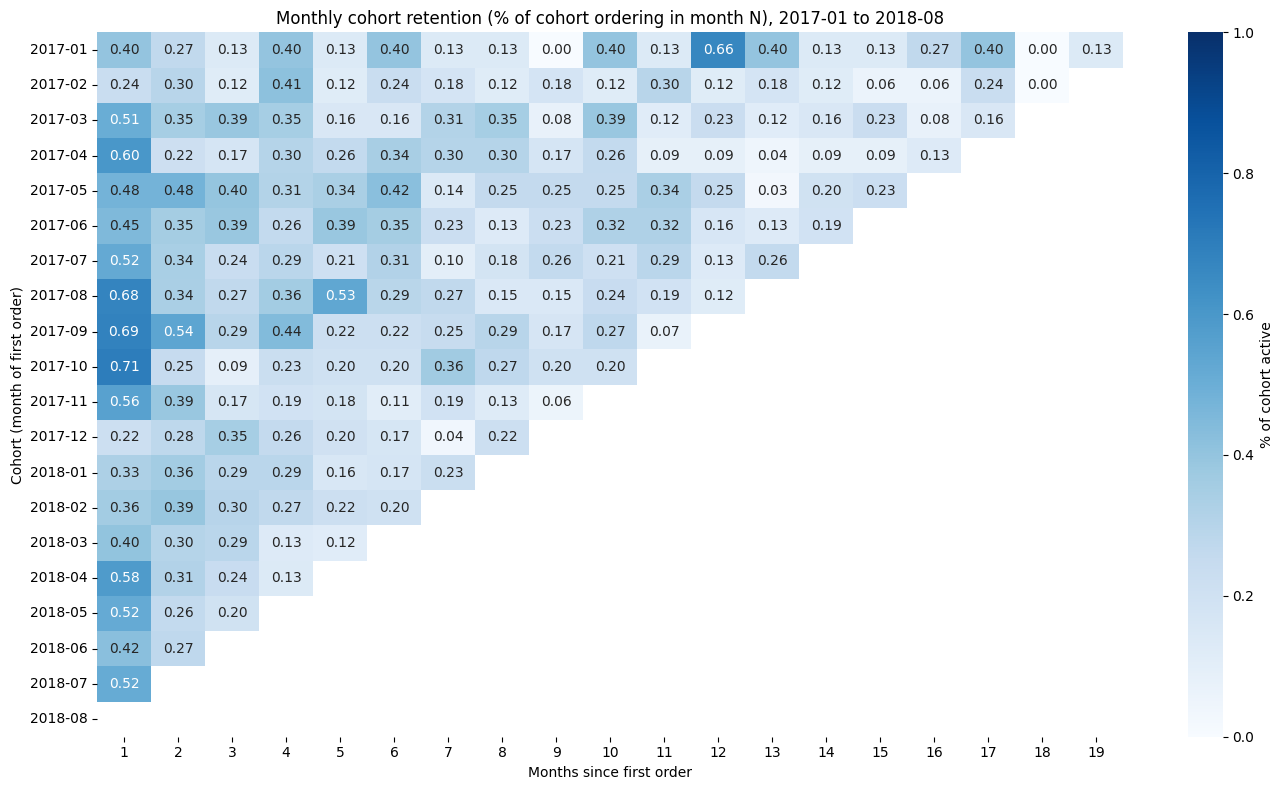

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = retention.drop(columns=[0])          # drop month 0 (always 100%)
plot_data.index = plot_data.index.astype(str)    # readable row labels

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(plot_data, annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1.0,                    # cap near the highest value
            cbar_kws={"label": "% of cohort active"}, ax=ax)
ax.set_title("Monthly cohort retention (% of cohort ordering in month N), 2017-01 to 2018-08")
ax.set_xlabel("Months since first order")
ax.set_ylabel("Cohort (month of first order)")
plt.tight_layout()
plt.show()

**Insight:** No cell in the matrix is above 0.71% (2017-10, month 1). Month 1 is the darkest column for most cohorts, and later months fade to roughly 0.1% to 0.4% with no second wave of returns. The 2017-08, 2017-09 and 2017-10 cohorts have the strongest month 1 (0.68%, 0.69%, 0.71%). The weakest month 1 is 2017-12 at 0.22%, followed by 2017-02 at 0.24%. The 2018 cohorts range from 0.33% to 0.58% in month 1. Cells beyond month 10 come from the oldest and smallest cohorts, where one person moves a value by 0.13 points. For example, 2017-01 shows 0.66% in month 12 but 0.00% in month 9, and nobody from the 2017-01 or 2017-02 cohorts ordered in month 18. Those swings are noise, not trends.

**Caution:** I have not tested whether any difference between cohorts is significant. Whatever caused the weak 2017-12 month 1 is a hypothesis, not a finding.

**Business implication (hypothesis):** retention is low at every customer age, not in one cohort or one month, so a one-off campaign aimed at a single period will not fix it. Month 1 is the most responsive window, so that is where a retention test would be worth running. Earlier in this notebook, 39.6% of repeat orders happened in the same calendar month as the first order, which points to the first weeks after purchase as the best time to reach customers.

In [11]:
# 'valid' = the 98,207 orders that count (canceled and unavailable already excluded)
snapshot = valid["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = valid.groupby("customer_unique_id").agg(
    last_order=("order_purchase_timestamp", "max"),   # latest purchase date
    frequency=("order_id", "count"),                    # number of orders
    monetary=("order_value", "sum"),                  # total spend
).reset_index()

rfm["recency_days"] = (snapshot - rfm["last_order"]).dt.days

print("snapshot date:", snapshot)
print("people:", len(rfm))
print("total orders:", rfm["frequency"].sum())
print("people with 1 order:", (rfm["frequency"] == 1).sum())
print("people with 2+ orders:", (rfm["frequency"] > 1).sum())
print(rfm[["recency_days", "frequency", "monetary"]].describe().round(2))

snapshot date: 2018-09-04 09:06:57
people: 94990
total orders: 98207
people with 1 order: 92102
people with 2+ orders: 2888
       recency_days  frequency  monetary
count      94990.00   94990.00  94990.00
mean         243.45       1.03    165.65
std          153.00       0.21    226.72
min            1.00       1.00      0.00
25%          119.00       1.00     63.10
50%          224.00       1.00    107.90
75%          352.00       1.00    182.93
max          729.00      16.00  13664.08


In [12]:
print(rfm["monetary"].sum())

15735527.03


In [13]:
print((rfm["monetary"] == 0).sum())

7


**Insight:** The RFM table has one row per person: 94,990 people and 98,207 orders, matching the earlier counts. 92,102 people (96.96%) have one order and 2,888 (3.04%) have two or more; the most orders by one person is 16. Recency is measured from 2018-09-04 and has a median of 224 days (range 1 to 729). Spend per person is skewed: the median is 107.90 but the mean is 165.65, and the maximum is 13,664.08. 7 people have a monetary value of 0 (orders without items). Total monetary is 15,735,527.03, which is higher than delivered-only revenue (15,419,773.75) because it includes valid orders that are not delivered; I have not split that gap by status.

**Caution:** Frequency is 1 for 97% of people, so it carries almost no information. The segments will mostly separate people by recency and spend, and any "Champions" group can hold at most the 2,888 repeat buyers.